In [112]:
import pandas as pd 

df = pd.read_csv("D:/air/airbnb-pricing-engine/data/listings.csv.gz")

In [113]:
unwanted_cols = ["neighborhood_overview",
"host_since",
"host_response_time",
"host_thumbnail_url",
"host_acceptance_rate",
"host_response_rate",
"host_verifications",
"neighbourhood",
"host_total_listings_count",
"host_neighbourhood",
"calendar_updated",
"instant_bookable",
"bathrooms",
]

In [114]:
df = df.drop(unwanted_cols,axis=1)

In [115]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 29918 entries, 0 to 29917
Data columns (total 77 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            29918 non-null  int64  
 1   listing_url                                   29918 non-null  str    
 2   scrape_id                                     29918 non-null  int64  
 3   last_scraped                                  29918 non-null  str    
 4   source                                        8906 non-null   str    
 5   name                                          29917 non-null  str    
 6   description                                   29772 non-null  str    
 7   picture_url                                   29918 non-null  str    
 8   host_id                                       29918 non-null  int64  
 9   host_url                                      29918 non-null  str    
 1

In [116]:
df.shape

(29918, 77)

In [117]:
df.columns.tolist()

['id',
 'listing_url',
 'scrape_id',
 'last_scraped',
 'source',
 'name',
 'description',
 'picture_url',
 'host_id',
 'host_url',
 'host_profile_id',
 'host_profile_url',
 'host_name',
 'hosts_time_as_user_years',
 'hosts_time_as_user_months',
 'hosts_time_as_host_years',
 'hosts_time_as_host_months',
 'host_location',
 'host_about',
 'host_is_superhost',
 'host_picture_url',
 'host_listings_count',
 'host_has_profile_pic',
 'host_identity_verified',
 'neighbourhood_cleansed',
 'neighbourhood_group_cleansed',
 'latitude',
 'longitude',
 'property_type',
 'room_type',
 'accommodates',
 'bathrooms_text',
 'bedrooms',
 'beds',
 'amenities',
 'price',
 'price_quote_checkin_date',
 'price_quote_checkout_date',
 'price_quote_total_price',
 'price_quote_price_per_night',
 'price_quote_raw',
 'minimum_nights',
 'maximum_nights',
 'minimum_minimum_nights',
 'maximum_minimum_nights',
 'minimum_maximum_nights',
 'maximum_maximum_nights',
 'minimum_nights_avg_ntm',
 'maximum_nights_avg_ntm',
 'ha

In [118]:
useful_cols = ["price","room_type", "property_type", "accommodates", "bedrooms","reviews_per_month",
               "beds","bathrooms_text","neighbourhood_cleansed", "latitude", "longitude","amenities",
              "minimum_nights", "availability_365","number_of_reviews", "number_of_reviews_ltm",
               'review_scores_rating','review_scores_accuracy','review_scores_cleanliness',
                'review_scores_checkin','review_scores_communication','review_scores_location','review_scores_value',
              "host_is_superhost", "host_identity_verified", "calculated_host_listings_count", "hosts_time_as_host_years"]


df_useful = df[useful_cols]

In [119]:
df_useful.info()

<class 'pandas.DataFrame'>
RangeIndex: 29918 entries, 0 to 29917
Data columns (total 27 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   price                           19406 non-null  str    
 1   room_type                       29918 non-null  str    
 2   property_type                   29918 non-null  str    
 3   accommodates                    29918 non-null  int64  
 4   bedrooms                        29879 non-null  float64
 5   reviews_per_month               21804 non-null  float64
 6   beds                            28764 non-null  float64
 7   bathrooms_text                  29811 non-null  str    
 8   neighbourhood_cleansed          29918 non-null  str    
 9   latitude                        29918 non-null  float64
 10  longitude                       29918 non-null  float64
 11  amenities                       29918 non-null  str    
 12  minimum_nights                  29910 non-n

In [120]:
df_useful["price"].head()

0        NaN
1    $164.55
2        NaN
3        NaN
4        NaN
Name: price, dtype: str

In [121]:
df_useful["price"] = df_useful["price"].replace("[$,]","",regex=True).str.replace(' ', '')

In [122]:
df_useful["price"] = df_useful['price'].astype(float)

In [123]:
df_useful["price"]

0            NaN
1         164.55
2            NaN
3            NaN
4            NaN
          ...   
29913        NaN
29914     689.00
29915     789.00
29916    2369.82
29917     313.17
Name: price, Length: 29918, dtype: float64

In [124]:
df_useful["price"].isna().sum()

np.int64(10512)

In [125]:
df_useful["price"].describe()

count    19406.000000
mean       310.165607
std        574.094115
min         17.700000
25%        103.682500
50%        182.445000
75%        337.000000
max      31537.820000
Name: price, dtype: float64

In [126]:
df_useful = df_useful.dropna(subset=["price"])

In [127]:
df_useful.isna().mean().sort_values(ascending=False)

review_scores_location            0.261208
review_scores_accuracy            0.261156
reviews_per_month                 0.261156
review_scores_cleanliness         0.261156
review_scores_checkin             0.261156
review_scores_communication       0.261156
review_scores_value               0.261156
review_scores_rating              0.261156
beds                              0.046841
bathrooms_text                    0.005153
bedrooms                          0.001649
minimum_nights                    0.000361
longitude                         0.000000
neighbourhood_cleansed            0.000000
latitude                          0.000000
room_type                         0.000000
price                             0.000000
property_type                     0.000000
accommodates                      0.000000
number_of_reviews_ltm             0.000000
amenities                         0.000000
availability_365                  0.000000
number_of_reviews                 0.000000
host_is_sup

In [128]:
import numpy as np
df_useful['has_reviews'] = np.where(df_useful['number_of_reviews'] > 0, 1, 0)

In [129]:
df_useful['has_reviews']

1        0
7        0
8        0
9        0
10       0
        ..
29912    1
29914    0
29915    0
29916    1
29917    1
Name: has_reviews, Length: 19406, dtype: int64

In [130]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")
df_useful[["beds"]] = imputer.fit_transform(df_useful[["beds"]])

In [131]:
imputer = SimpleImputer(strategy="median")
df_useful[["bedrooms"]] = imputer.fit_transform(df_useful[["bedrooms"]])

In [132]:
df_useful = df_useful.dropna(subset=["minimum_nights"])

In [133]:
df_useful["minimum_nights"]

1        31.0
7        30.0
8        30.0
9        30.0
10       30.0
         ... 
29912     1.0
29914     1.0
29915     1.0
29916     1.0
29917    30.0
Name: minimum_nights, Length: 19399, dtype: float64

In [134]:
df_useful["bathrooms_text"].value_counts()

bathrooms_text
1 bath               8572
1 shared bath        3680
1 private bath       3367
2 baths              1411
2 shared baths        577
1.5 baths             505
1.5 shared baths      327
2.5 baths             193
3 baths               175
0 shared baths        109
0 baths                62
3.5 baths              60
4 baths                43
3 shared baths         32
Half-bath              27
Private half-bath      23
Shared half-bath       21
4 shared baths         20
4.5 baths              20
2.5 shared baths       17
2 private baths         8
5 shared baths          7
5 baths                 7
3.5 shared baths        7
5.5 baths               5
6 baths                 4
3 private baths         4
7.5 baths               3
6.5 baths               2
9 baths                 2
10 baths                2
7 baths                 2
4 private baths         2
6 shared baths          1
10.5 baths              1
15.5 baths              1
Name: count, dtype: int64

In [135]:
df_useful.isna().mean().sort_values(ascending=False)

review_scores_location            0.261302
reviews_per_month                 0.261251
review_scores_checkin             0.261251
review_scores_accuracy            0.261251
review_scores_cleanliness         0.261251
review_scores_rating              0.261251
review_scores_value               0.261251
review_scores_communication       0.261251
bathrooms_text                    0.005155
accommodates                      0.000000
price                             0.000000
room_type                         0.000000
amenities                         0.000000
longitude                         0.000000
latitude                          0.000000
neighbourhood_cleansed            0.000000
beds                              0.000000
bedrooms                          0.000000
property_type                     0.000000
number_of_reviews_ltm             0.000000
minimum_nights                    0.000000
availability_365                  0.000000
number_of_reviews                 0.000000
host_is_sup

In [136]:
df_useful.info()

<class 'pandas.DataFrame'>
Index: 19399 entries, 1 to 29917
Data columns (total 28 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   price                           19399 non-null  float64
 1   room_type                       19399 non-null  str    
 2   property_type                   19399 non-null  str    
 3   accommodates                    19399 non-null  int64  
 4   bedrooms                        19399 non-null  float64
 5   reviews_per_month               14331 non-null  float64
 6   beds                            19399 non-null  float64
 7   bathrooms_text                  19299 non-null  str    
 8   neighbourhood_cleansed          19399 non-null  str    
 9   latitude                        19399 non-null  float64
 10  longitude                       19399 non-null  float64
 11  amenities                       19399 non-null  str    
 12  minimum_nights                  19399 non-null  

In [137]:
df_useful["bathrooms"] = (
    df_useful["bathrooms_text"]
    .str.extract(r"(\d+\.?\d*)")[0]
    .astype(float)
)


In [138]:
half_mask = df_useful["bathrooms_text"].str.contains("half", case=False, na=False)

df_useful.loc[half_mask, "bathrooms"] = 0.5

In [139]:
before = len(df_useful)
df_useful = df_useful[df_useful["bathrooms"].notna()]
after = len(df_useful)

print(f"Removed {before - after} rows with missing bathroom info")

Removed 100 rows with missing bathroom info


In [140]:
df_useful["shared_bath"] = (
    df_useful["bathrooms_text"]
    .str.contains("shared", case=False, na=False)
    .astype(int)
)

In [141]:
df_useful = df_useful.drop(columns=["bathrooms_text"])

In [143]:
df_useful["bathrooms"].isna().sum()

np.int64(0)

In [144]:
df_useful["bathrooms"].value_counts().sort_index()

bathrooms
0.0       171
0.5        71
1.0     15619
1.5       832
2.0      1996
2.5       210
3.0       211
3.5        67
4.0        65
4.5        20
5.0        14
5.5         5
6.0         5
6.5         2
7.0         2
7.5         3
9.0         2
10.0        2
10.5        1
15.5        1
Name: count, dtype: int64

In [145]:
df_useful["shared_bath"].value_counts()

shared_bath
0    14501
1     4798
Name: count, dtype: int64

In [146]:
df_useful["price"].describe()

count    19299.000000
mean       302.937514
std        548.266486
min         17.700000
25%        103.360000
50%        181.600000
75%        333.905000
max      31537.820000
Name: price, dtype: float64

In [149]:
print(df_useful["price"].quantile(0.01))
print(df_useful["price"].quantile(0.05))
print(df_useful["price"].quantile(0.25))
print(df_useful["price"].quantile(0.50))
print(df_useful["price"].quantile(0.75))
print(df_useful["price"].quantile(0.95))
print(df_useful["price"].quantile(0.99))

43.27
55.028000000000006
103.36
181.6
333.905
860.2499999999978
1849.268000000001


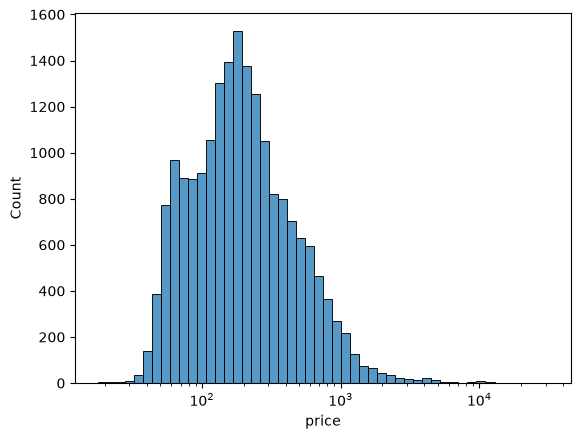

In [171]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.histplot(df_useful,x="price", bins=50,log_scale=True )
plt.show()

In [168]:
# 1. Let's look at the price distribution
print(df_useful['price'].describe())
print("99th Percentile:", df_useful['price'].quantile(0.99))

# 2. Check how many NaNs are left across the dataframe
print(df_useful.isna().sum())


count    19299.000000
mean       302.937514
std        548.266486
min         17.700000
25%        103.360000
50%        181.600000
75%        333.905000
max      31537.820000
Name: price, dtype: float64
99th Percentile: 1849.268000000001
price                                0
room_type                            0
property_type                        0
accommodates                         0
bedrooms                             0
reviews_per_month                 5006
beds                                 0
neighbourhood_cleansed               0
latitude                             0
longitude                            0
amenities                            0
minimum_nights                       0
availability_365                     0
number_of_reviews                    0
number_of_reviews_ltm                0
review_scores_rating              5006
review_scores_accuracy            5006
review_scores_cleanliness         5006
review_scores_checkin             5006
review_scores_commun

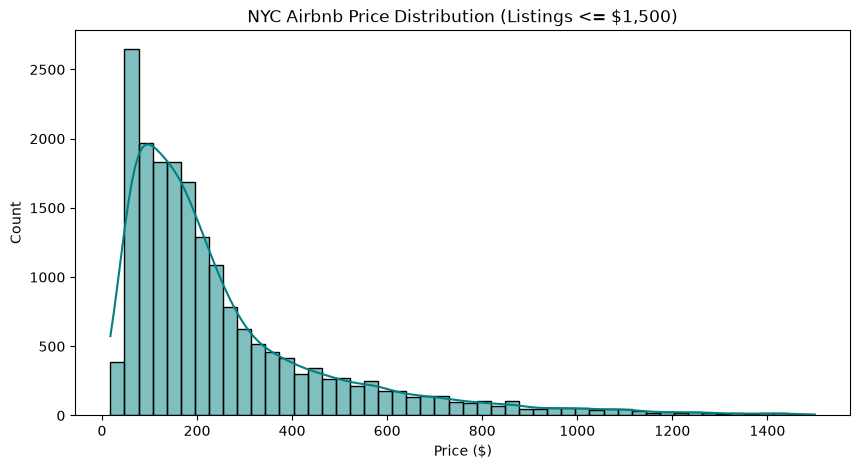

In [169]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
# Filter visually to listings under $1,500 to see the distribution clearly
sns.histplot(df_useful[df_useful['price'] <= 1500]['price'], bins=50, kde=True, color='teal')
plt.title('NYC Airbnb Price Distribution (Listings <= $1,500)')
plt.xlabel('Price ($)')
plt.ylabel('Count')
plt.show()


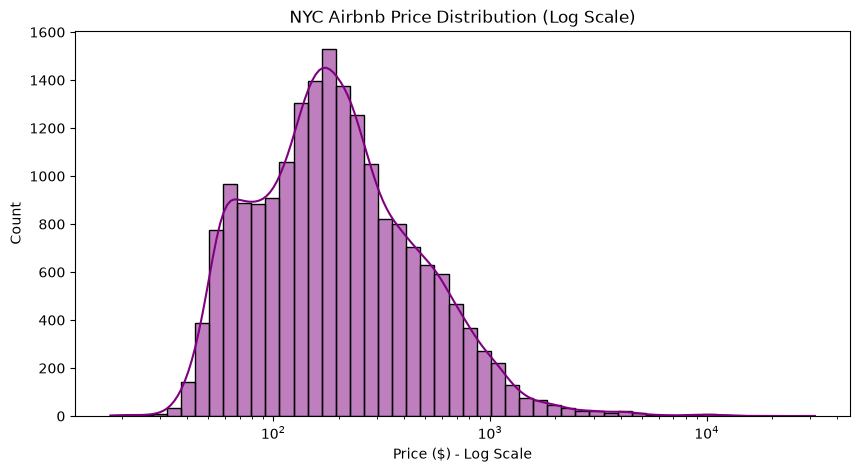

In [170]:
import numpy as np

plt.figure(figsize=(10, 5))
sns.histplot(df_useful['price'], bins=50, kde=True, log_scale=True, color='purple')
plt.title('NYC Airbnb Price Distribution (Log Scale)')
plt.xlabel('Price ($) - Log Scale')
plt.ylabel('Count')
plt.show()


In [172]:
# Apply the upper cutoff
upper_limit = 1500
df_clean = df_useful[df_useful['price'] <= upper_limit].copy()

# Calculate how many rows were removed
removed_count = len(df_useful) - len(df_clean)
pct_removed = (removed_count / len(df_useful)) * 100

print(f"Removed {removed_count} outlier listings ({pct_removed:.2f}%) above ${upper_limit}.")
print(f"New dataset shape: {df_clean.shape}")


Removed 274 outlier listings (1.42%) above $1500.
New dataset shape: (19025, 29)


In [173]:
# Convert 't'/'f' to 1/0
for col in ['host_is_superhost', 'host_identity_verified']:
    df_clean[col] = df_clean[col].map({'t': 1, 'f': 0})

# Double check that they converted perfectly
print(df_clean[['host_is_superhost', 'host_identity_verified']].dtypes)
print(df_clean[['host_is_superhost', 'host_identity_verified']].head())


host_is_superhost         int64
host_identity_verified    int64
dtype: object
    host_is_superhost  host_identity_verified
1                   0                       1
7                   0                       1
8                   0                       1
9                   0                       1
10                  0                       1


In [177]:
import os

# Create the data directory if it doesn't exist
os.makedirs('data', exist_ok=True)

# Save the filtered and type-fixed dataframe
df_clean.to_csv('data/listings_clean.csv', index=False)
print(f"Dataset saved! Final shape: {df_clean.shape}")


Dataset saved! Final shape: (19025, 29)
